In [59]:
import sys
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sys.path.append(str(Path().resolve().parent/"src"))
from features import add_geometry_features

results = {}

In [60]:
# helpers
def evaluate(y_true,y_pred):
    mae = mean_absolute_error(y_true,y_pred)
    rmse = root_mean_squared_error(y_true,y_pred)
    r2 = r2_score(y_true,y_pred)
    return mae, rmse, r2

# Mean Baseline
Taking the mean of both the cl and cd and using that as the prediction

In [61]:
# Load the CSV data into dataframe
CSV_PATH = Path().resolve().parent/"data"/"processed"/"airfrans_coefficients.csv"
df = pd.read_csv(CSV_PATH)


# Split dataframe into train and test data
train_df = df.loc[df["split_full"]=="train"]
test_df = df.loc[df["split_full"]=="test"]

# Get mean cl and cd value from training data
mean_cl = train_df["cl"].mean()
mean_cd = train_df["cd"].mean()

print(f"Mean cl from training data: {mean_cl}")
print(f"Mean cd from training data: {mean_cd}")

# Predict the values by solely taking the mean
cl_pred = np.full(len(test_df),mean_cl)
cd_pred = np.full(len(test_df),mean_cd)

# Scoreing the prediction
cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_pred)
cd_mae, cd_rmse, cd_r2 = evaluate(test_df["cd"],cd_pred)

# Outputs
print("\n--- Cl (coefficient of Lift) ---")
print(f"MAE: {cl_mae}")
print(f"RMSE: {cl_rmse}")
print(f"R^2: {cl_r2}")

print("--- Cd (coefficient of Drag) ---")
print(f"MAE: {cd_mae}")
print(f"RMSE: {cd_rmse}")
print(f"R^2: {cd_r2}")

# add to the results
results["mean_baseline"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2,"cd_mae":cd_mae,"cd_rmse":cd_rmse,"cd_r2":cd_r2}

Mean cl from training data: 0.6767168151116846
Mean cd from training data: 0.012495524718604436

--- Cl (coefficient of Lift) ---
MAE: 0.4982478689429241
RMSE: 0.579817991426866
R^2: -0.0020055116225636826
--- Cd (coefficient of Drag) ---
MAE: 0.0034340043936832883
RMSE: 0.004728631989820384
R^2: -0.0011017976425085063


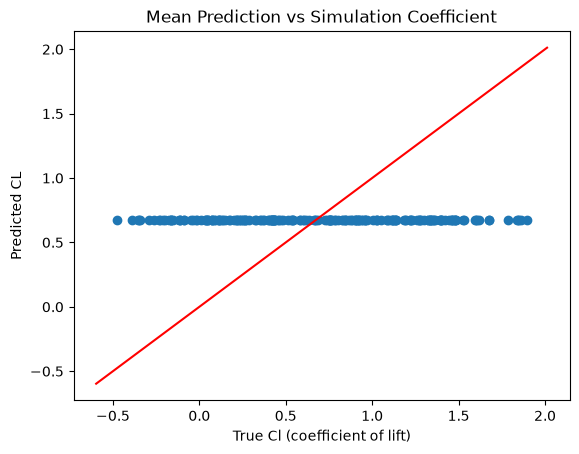

In [62]:
# Visualisation of the pred cl vs true
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["cl"],cl_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Mean Prediction vs Simulation Coefficient")
ax.set_ylabel("Predicted CL")
ax.set_xlabel("True Cl (coefficient of lift)")
plt.show()

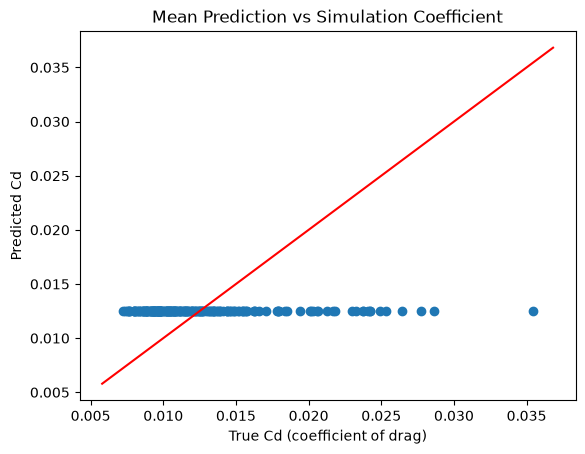

In [63]:
# Visualisation of the pred cd vs true
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["cd"],cd_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Mean Prediction vs Simulation Coefficient")
ax.set_ylabel("Predicted Cd")
ax.set_xlabel("True Cd (coefficient of drag)")
plt.show()

In [64]:
print(results)

{'mean_baseline': {'cl_mae': 0.4982478689429241, 'cl_rmse': 0.579817991426866, 'cl_r2': -0.0020055116225636826, 'cd_mae': 0.0034340043936832883, 'cd_rmse': 0.004728631989820384, 'cd_r2': -0.0011017976425085063}}


# Thin-Airfoil Theory

$Cl = 2\pi \times (\alpha-\alpha_{lo})$

Assumptions:
- The airfoil is very thin: airfoil is treated as just its camber line
- The angle of attack is small
- the air has no viscosity
- The flow leaves the sharp trailing edge smoothly


In [65]:
cl_pred = 2*np.pi * np.deg2rad(test_df["angleOfAttack"])

cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_pred)

print("\n--- Cl (coefficient of Lift) ---")
print(f"MAE: {cl_mae}")
print(f"RMSE: {cl_rmse}")
print(f"R^2: {cl_r2}")

results["thin_airfoil_theory"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2}


--- Cl (coefficient of Lift) ---
MAE: 0.21423209633326046
RMSE: 0.29375180477444884
R^2: 0.7428137043370256


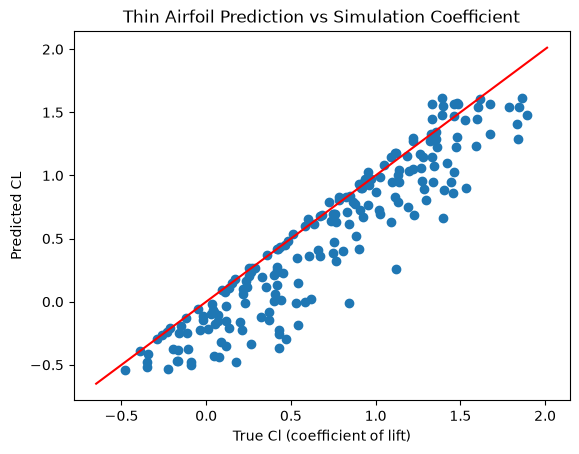

In [66]:
# Visualisation of thin-Airfoil Theory
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["cl"],cl_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Thin Airfoil Prediction vs Simulation Coefficient")
ax.set_ylabel("Predicted CL")
ax.set_xlabel("True Cl (coefficient of lift)")
plt.show()

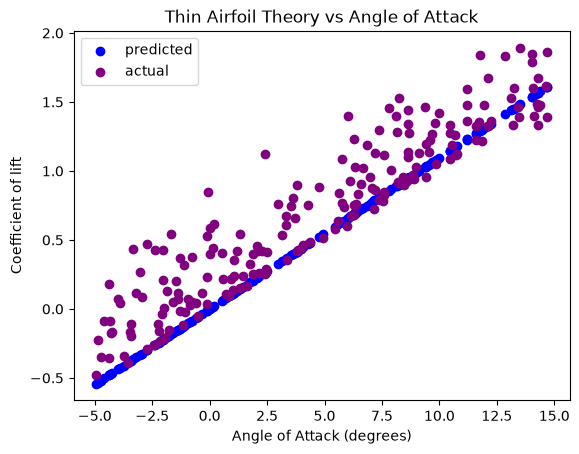

In [67]:
# visualisation of thin-airfoil theory against angle of attack
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["angleOfAttack"],cl_pred, c="Blue", label="predicted")
ax.scatter(test_df["angleOfAttack"],test_df["cl"],c="Purple", label="actual")

# plot y=x as ideal line
# lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
#ax.plot(lims, lims,c="red")

ax.set_title("Thin Airfoil Theory vs Angle of Attack")
ax.set_ylabel("Coefficient of lift")
ax.set_xlabel("Angle of Attack (degrees)")
ax.legend()
plt.show()

# Linear Regression
In order for linear regression to make use of as much information as possible, the 4 and 5 digit values need to be converted into a universal values:
- `max_camber` = m/100 or calculated from camber line
- `camber_pos` = p/10 or calculated from camber line
- `thickness` = XX/100 for both
- `reflex` = 0 or q as 0 or 1

In [68]:
# Use camber_line function to get max camber and position

import airfrans as af
from airfrans.naca_generator import camber_line
DATA_PATH = Path().resolve().parent/"data"/"Dataset"

sim = df.iloc[0]
simulation = af.Simulation(DATA_PATH,sim["name"])

rang = np.linspace(0,1,1001)
range_line = camber_line([sim["L"],sim["P"],sim["Q"]],rang)
range_max_camber = np.max(range_line[0])
range_position = rang[np.argmax(range_line[0])]

print(f"Range: {range_max_camber} {range_position}")

Range: 0.04580895799385703 0.271


Used Above cell to build `add_geometry_features()` in `src/features.py`

In [72]:
# Add the geometric features to the dataframe
df = add_geometry_features(df)
df.describe()

,inletVelocity,Re,angleOfAttack,M,L,P,XX,cl,cd,cl_p_lib,...,thickness,reflex,max_camber,camber_pos,thickness,reflex,max_camber,camber_pos,thickness,reflex
count,1000.000000,1.000000e+03,1000.000000,489.000000,511.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,62.191042,3.986605e+06,4.526535,3.556771,1.946027,4.361363,12.510710,0.681905,0.012527,0.681780,...,0.125107,0.279000,0.028741,0.294639,0.125107,0.279000,0.028741,0.294639,0.125107,0.279000
std,17.885649,1.146516e+06,5.475841,2.042853,1.121604,2.247985,4.269738,0.573235,0.004943,0.573179,...,0.042697,0.448732,0.018331,0.167837,0.042697,0.448732,0.018331,0.167837,0.042697,0.448732
min,31.283000,2.005321e+06,-4.940000,0.006000,0.004000,0.000000,5.008000,-0.533626,0.006905,-0.533772,...,0.050080,0.000000,0.000050,0.000000,0.050080,0.000000,0.000050,0.000000,0.050080,0.000000
25%,46.446000,2.977308e+06,-0.214000,1.805000,0.981500,3.047750,9.081500,0.217207,0.009248,0.217020,...,0.090815,0.000000,0.013739,0.195750,0.090815,0.000000,0.013739,0.195750,0.090815,0.000000
50%,62.404000,4.000256e+06,3.993500,3.498000,1.878000,4.654500,12.578000,0.683125,0.010743,0.683064,...,0.125780,0.000000,0.026486,0.289150,0.125780,0.000000,0.026486,0.289150,0.125780,0.000000
75%,77.353750,4.958574e+06,9.031500,5.364000,2.908500,6.210000,16.137500,1.165895,0.014239,1.165780,...,0.161375,1.000000,0.041357,0.378775,0.161375,1.000000,0.041357,0.378775,0.161375,1.000000
max,93.592000,5.999487e+06,14.926000,6.998000,3.993000,7.969000,19.989000,1.893270,0.045949,1.893076,...,0.199890,1.000000,0.069980,0.699200,0.199890,1.000000,0.069980,0.699200,0.199890,1.000000
